# Практичне заняття № 1 — Логістична регресія

**Завдання.** Використовуючи модель логістичної регресії, виконати класифікацію
програмного забезпечення на **шкідливе** та **безпечне** на даних датасету
[UCI Malware Executable Detection](https://www.kaggle.com/datasets/piyushrumao/malware-executable-detection).

**Про дані.** 373 виконуваних файли Windows, для кожного — 531 бінарна ознака
(`F_1 … F_531`), утворена з гібридних характеристик: шістнадцяткові послідовності
байтів + виклики DLL. Колонка `Label` — `malicious` / `non-malicious`.

**Що робить цю задачу цікавою (і чому «точність» тут бреше):**

1. **Дисбаланс класів** — 301 шкідливий проти 72 безпечних. Модель, яка завжди
   каже «шкідливий», отримає 80.7 % точності, нічого не навчившись.
2. **p > n** — ознак (531) більше, ніж прикладів (373). Методичка прямо попереджає:
   *«кількість прикладів має в кілька разів перевищувати кількість вхідних ознак»*.
   Тут це порушено вп'ятеро, тож без регуляризації та відбору ознак модель
   перенавчиться.
3. **Ціна помилки несиметрична.** Для антивіруса хибнопозитивне спрацювання
   (безпечний файл названо шкідливим) часто гірше за пропуск: користувач втрачає
   робочу програму. А дисбаланс штовхає модель саме в цей бік.

In [1]:
# --- Підготовка даних -------------------------------------------------------
# Ноутбук має запускатися і локально, і в Colab. Якщо потрібного файлу немає,
# він завантажується з Kaggle. Кількість колонок перевіряється одразу: Kaggle
# може оновити версію набору, і краще впасти тут, ніж мовчки отримати інші
# числа, ніж у звіті.
import importlib.util
import shutil
import subprocess
import sys
from pathlib import Path


def _in_colab():
    if "google.colab" in sys.modules:
        return True
    try:
        return importlib.util.find_spec("google.colab") is not None
    except (ImportError, ValueError):
        # find_spec імпортує батьківський пакет; без нього — це не Colab
        return False


IN_COLAB = _in_colab()
DATA = Path("data"); DATA.mkdir(exist_ok=True)
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)

# (локальна назва, slug на Kaggle, файл усередині набору, очікувано колонок)
DATASETS = [
    ('uci_malware_detection.csv', 'piyushrumao/malware-executable-detection',
     'uci_malware_detection.csv', 532),
]


def _ensure_packages():
    """У Colab більшість пакетів уже є; доставляємо лише те, чого бракує."""
    missing = [p for p in ("pandas", "sklearn", "matplotlib", "seaborn", "kagglehub")
               if importlib.util.find_spec(p) is None]
    if missing:
        names = {"sklearn": "scikit-learn"}
        pkgs = [names.get(m, m) for m in missing]
        print("встановлюю:", ", ".join(pkgs))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)


def _check(path, ncols):
    import pandas as pd
    got = pd.read_csv(path, nrows=1).shape[1]
    if got != ncols:
        raise ValueError(f"{path.name}: очікували {ncols} колонок, отримали {got}")


def _ensure(local, slug, member, ncols):
    dst = DATA / local
    if dst.exists():
        _check(dst, ncols)
        print(f"на місці: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    if importlib.util.find_spec("kagglehub"):
        import kagglehub
        print(f"завантажую {slug} …")
        root = Path(kagglehub.dataset_download(slug))
        src = next(iter(root.rglob(member)), None)
        if src is None:   # назву файлу в наборі могли змінити — беремо найбільший CSV
            src = max(root.rglob("*.csv"), key=lambda f: f.stat().st_size)
        shutil.copy(src, dst)
        _check(dst, ncols)
        print(f"готово: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    raise FileNotFoundError(
        f"{dst} не знайдено. Візьміть набір за адресою "
        f"https://www.kaggle.com/datasets/{slug} і покладіть файл у {DATA}/ "
        f"під назвою {local}."
    )


if IN_COLAB:
    _ensure_packages()
for _args in DATASETS:
    _ensure(*_args)


на місці: data/uci_malware_detection.csv (0.4 МБ)


In [2]:
# --- Імпорти та глобальні налаштування ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_score)
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectFromModel, SelectKBest, chi2
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve, classification_report)

RANDOM_STATE = 42           # фіксуємо зерно — щоб результати відтворювались
ASSETS = Path("assets")     # сюди зберігаємо рисунки для звіту
ASSETS.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
np.random.seed(RANDOM_STATE)

## 1. Завантаження та первинний огляд даних

In [3]:
df = pd.read_csv("data/uci_malware_detection.csv")

print(f"Розмір таблиці: {df.shape[0]} рядків × {df.shape[1]} колонок")
print(f"Пропущених значень: {df.isna().sum().sum()}")
print()
print("Розподіл класів:")
print(df["Label"].value_counts().to_string())

# Цільова змінна: 1 = шкідливий (позитивна подія), 0 = безпечний.
# Методичка вимагає явно визначити, що є позитивною подією. Обираємо «шкідливий»
# за аналогією з прикладом про діагностику: позитивний результат — «Хворий».
y = (df["Label"] == "malicious").astype(int)
X = df.drop(columns=["Label"])

print(f"\nЧастка позитивного класу: {y.mean():.1%}")

Розмір таблиці: 373 рядків × 532 колонок
Пропущених значень: 0

Розподіл класів:
Label
malicious        301
non-malicious     72

Частка позитивного класу: 80.7%


In [4]:
# --- Структура ознакового простору ---
# Усі ознаки бінарні (0/1): або послідовність байтів / виклик DLL присутній, або ні.
unique_vals = np.unique(X.values)
zero_frac = (X.values == 0).mean()
constant_cols = X.columns[X.nunique() == 1]

print(f"Множина значень усіх ознак: {unique_vals}")
print(f"Розрідженість (частка нулів): {zero_frac:.1%}")
print(f"Константних (завжди 0) ознак: {len(constant_cols)}")
print(f"Співвідношення ознак до прикладів: {X.shape[1]} / {X.shape[0]} = {X.shape[1]/X.shape[0]:.2f}")

Множина значень усіх ознак: [0 1]
Розрідженість (частка нулів): 80.3%
Константних (завжди 0) ознак: 28
Співвідношення ознак до прикладів: 531 / 373 = 1.42


Оскільки всі ознаки вже в одній шкалі `{0, 1}`, стандартизація (`StandardScaler`)
не потрібна — вона знадобилась би для різномасштабних числових ознак. Але
константні колонки несуть нуль інформації, тож їх прибираємо: методичка радить
*«штучно спрощувати структуру регресійної моделі, залишаючи найбільш істотні ознаки»*.

In [5]:
# Прибираємо ознаки, які не змінюються — вони не можуть нічого розрізнити
X = X.drop(columns=constant_cols)
print(f"Залишилось ознак після видалення константних: {X.shape[1]}")

Залишилось ознак після видалення константних: 503


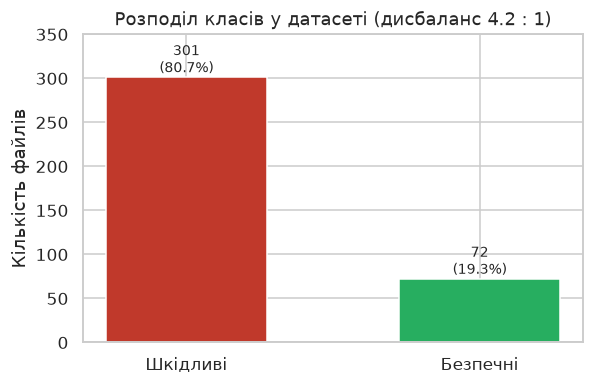

In [6]:
# --- Рисунок 1: баланс класів ---
fig, ax = plt.subplots(figsize=(5.5, 3.6))
counts = df["Label"].value_counts()
bars = ax.bar(["Шкідливі", "Безпечні"], [counts["malicious"], counts["non-malicious"]],
              color=["#c0392b", "#27ae60"], width=0.55)
for b, v in zip(bars, [counts["malicious"], counts["non-malicious"]]):
    ax.text(b.get_x() + b.get_width()/2, v + 6, f"{v}\n({v/len(df):.1%})",
            ha="center", fontsize=9)
ax.set_ylabel("Кількість файлів")
ax.set_title("Розподіл класів у датасеті (дисбаланс 4.2 : 1)")
ax.set_ylim(0, 350)
plt.tight_layout()
plt.savefig(ASSETS / "01-class-balance.png", bbox_inches="tight")
plt.show()

## 2. Базова лінія: чому точність не можна використовувати саму по собі

Перш ніж навчати будь-що, треба знати, який результат дає *тривіальна* модель.
`DummyClassifier(strategy="most_frequent")` завжди відповідає «шкідливий».

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE,
    stratify=y,          # зберігаємо пропорцію класів у train і test
)
print(f"Навчальна вибірка: {X_train.shape[0]} прикладів "
      f"({y_train.sum()} шкідливих / {(1-y_train).sum()} безпечних)")
print(f"Тестова вибірка:   {X_test.shape[0]} прикладів "
      f"({y_test.sum()} шкідливих / {(1-y_test).sum()} безпечних)")

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
print(f"\n«Завжди шкідливий» — точність: {accuracy_score(y_test, dummy_pred):.1%}")
print(f"«Завжди шкідливий» — повнота щодо безпечних: "
      f"{recall_score(y_test, dummy_pred, pos_label=0):.1%}  ← жодного безпечного файлу не знайдено")

Навчальна вибірка: 279 прикладів (225 шкідливих / 54 безпечних)
Тестова вибірка:   94 прикладів (76 шкідливих / 18 безпечних)

«Завжди шкідливий» — точність: 80.9%
«Завжди шкідливий» — повнота щодо безпечних: 0.0%  ← жодного безпечного файлу не знайдено


**Висновок базової лінії.** 80.6 % точності — і при цьому модель не розпізнала
*жодного* безпечного файлу. Саме тому далі скрізь дивимось на **precision**,
**recall**, **F1** та **матрицю невідповідностей**, а не на самy точність.

## 3. Логістична регресія: базова модель

In [8]:
# solver='liblinear' добре працює на малих вибірках і підтримує L1/L2.
# C — обернений коефіцієнт регуляризації: менше C = сильніша регуляризація.
logreg = LogisticRegression(
    l1_ratio=0, C=1.0, solver="liblinear",
    max_iter=5000, random_state=RANDOM_STATE,
)
logreg.fit(X_train, y_train)

y_pred = logreg.predict(X_test)
y_proba = logreg.predict_proba(X_test)[:, 1]   # Λ(θᵀx) — ймовірність класу «шкідливий»

print(classification_report(y_test, y_pred,
                            target_names=["безпечний", "шкідливий"], digits=3))

              precision    recall  f1-score   support

   безпечний      1.000     1.000     1.000        18
   шкідливий      1.000     1.000     1.000        76

    accuracy                          1.000        94
   macro avg      1.000     1.000     1.000        94
weighted avg      1.000     1.000     1.000        94



In [9]:
def evaluate(name, y_true, y_pred, y_proba):
    # Зводимо всі метрики в один рядок — щоб потім порівнювати моделі таблицею
    return {
        "Модель": name,
        "Точність": accuracy_score(y_true, y_pred),
        "Precision (шкідл.)": precision_score(y_true, y_pred, zero_division=0),
        "Recall (шкідл.)": recall_score(y_true, y_pred, zero_division=0),
        "Recall (безпеч.)": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba),
    }

results = [
    evaluate("Базова лінія (завжди «шкідливий»)", y_test, dummy_pred,
             dummy.predict_proba(X_test)[:, 1]),
    evaluate("Логістична регресія (L2, C=1)", y_test, y_pred, y_proba),
]
pd.DataFrame(results).set_index("Модель").round(3)

,Точність,Precision (шкідл.),Recall (шкідл.),Recall (безпеч.),F1,ROC-AUC,PR-AUC
Модель,,,,,,,
Базова лінія (завжди «шкідливий»),0.809,0.809,1.0,0.0,0.894,0.5,0.809
"Логістична регресія (L2, C=1)",1.000,1.000,1.0,1.0,1.000,1.0,1.000


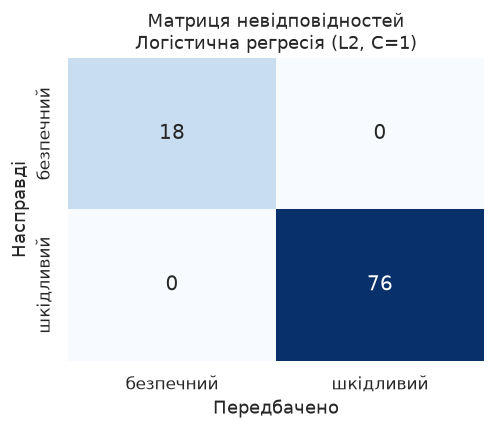

Хибнопозитивні (безпечний → шкідливий): 0  ← користувач втрачає робочу програму
Хибнонегативні (шкідливий → безпечний): 0  ← малваре проходить крізь фільтр


In [10]:
# --- Рисунок 2: матриця невідповідностей ---
fig, ax = plt.subplots(figsize=(4.6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["безпечний", "шкідливий"],
            yticklabels=["безпечний", "шкідливий"], annot_kws={"size": 13})
ax.set_xlabel("Передбачено")
ax.set_ylabel("Насправді")
ax.set_title("Матриця невідповідностей\nЛогістична регресія (L2, C=1)")
plt.tight_layout()
plt.savefig(ASSETS / "02-confusion-matrix.png", bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Хибнопозитивні (безпечний → шкідливий): {fp}  ← користувач втрачає робочу програму")
print(f"Хибнонегативні (шкідливий → безпечний): {fn}  ← малваре проходить крізь фільтр")

## 4. Чесніша оцінка: перехресна перевірка

Тестова вибірка містить лише ~18 безпечних файлів. Одна метрика на такій
кількості — це майже шум: помилка на двох файлах зсуває recall на 11 пунктів.
Тому переходимо на стратифіковану 5-блокову перехресну перевірку по **всіх** даних.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]

cv_res = cross_validate(
    LogisticRegression(l1_ratio=0, C=1.0, solver="liblinear",
                       max_iter=5000, random_state=RANDOM_STATE),
    X, y, cv=cv, scoring=scoring,
)

cv_table = pd.DataFrame({
    "Метрика": ["Точність", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"],
    "Середнє": [cv_res[f"test_{s}"].mean() for s in scoring],
    "Ст. відхилення": [cv_res[f"test_{s}"].std() for s in scoring],
}).set_index("Метрика").round(3)
cv_table

,Середнє,Ст. відхилення
Метрика,,
Точність,0.995,0.007
Precision,0.997,0.007
Recall,0.997,0.007
F1,0.997,0.004
ROC-AUC,1.000,0.000
PR-AUC,1.000,0.000


## 5. Боротьба з дисбалансом: `class_weight="balanced"`

Параметр `class_weight="balanced"` домножує внесок кожного класу у функцію втрат
на величину, обернену до його частоти. Тобто помилка на рідкісному «безпечному»
класі коштує моделі приблизно вчетверо дорожче.

In [12]:
logreg_bal = LogisticRegression(
    l1_ratio=0, C=1.0, solver="liblinear", class_weight="balanced",
    max_iter=5000, random_state=RANDOM_STATE,
).fit(X_train, y_train)

y_pred_bal = logreg_bal.predict(X_test)
y_proba_bal = logreg_bal.predict_proba(X_test)[:, 1]

results.append(evaluate("Логістична регресія (balanced)", y_test, y_pred_bal, y_proba_bal))
print(classification_report(y_test, y_pred_bal,
                            target_names=["безпечний", "шкідливий"], digits=3))

              precision    recall  f1-score   support

   безпечний      1.000     1.000     1.000        18
   шкідливий      1.000     1.000     1.000        76

    accuracy                          1.000        94
   macro avg      1.000     1.000     1.000        94
weighted avg      1.000     1.000     1.000        94



## 6. Відбір ознак: приборкання p > n

531 ознака на 280 навчальних прикладів — модель має більше свободи, ніж даних.
L1-регуляризація (Lasso) занулює коефіцієнти неінформативних ознак, тобто робить
відбір автоматично. Це і є те «штучне спрощення структури регресійної моделі»,
про яке говорить методичка.

**Обережно з `threshold="median"`.** Це типова пастка: якщо L1 занулила більше
половини коефіцієнтів, то медіана важливості дорівнює нулю, і фільтр
«важливість ≥ медіани» пропускає **всі** ознаки — відбір мовчки не відбувається.
Тому нижче перевіряємо кількість ненульових коефіцієнтів явно.

In [13]:
l1 = LogisticRegression(
    l1_ratio=1, C=0.1, solver="liblinear",
    max_iter=5000, random_state=RANDOM_STATE,
).fit(X_train, y_train)

nonzero = int((l1.coef_[0] != 0).sum())
median_importance = np.median(np.abs(l1.coef_[0]))
print(f"Ненульових коефіцієнтів після L1 (C=0.1): {nonzero} з {X_train.shape[1]}")
print(f"Медіана |θ|: {median_importance:.6f}   ← якщо 0, то threshold='median' не відсіє нічого")

Ненульових коефіцієнтів після L1 (C=0.1): 3 з 503
Медіана |θ|: 0.000000   ← якщо 0, то threshold='median' не відсіє нічого


In [14]:
# Відбираємо лише ознаки з дійсно ненульовою вагою
selector = SelectFromModel(l1, threshold=1e-10, prefit=True)
kept = selector.get_support()
print(f"Ознак після відбору: {kept.sum()}")

X_train_sel, X_test_sel = selector.transform(X_train.values), selector.transform(X_test.values)

logreg_sel = LogisticRegression(
    l1_ratio=0, C=1.0, solver="liblinear", class_weight="balanced",
    max_iter=5000, random_state=RANDOM_STATE,
).fit(X_train_sel, y_train)

y_pred_sel = logreg_sel.predict(X_test_sel)
y_proba_sel = logreg_sel.predict_proba(X_test_sel)[:, 1]

results.append(evaluate(f"L1-відбір ({kept.sum()} ознак) + balanced",
                        y_test, y_pred_sel, y_proba_sel))
pd.DataFrame(results).set_index("Модель").round(3)

Ознак після відбору: 3


,Точність,Precision (шкідл.),Recall (шкідл.),Recall (безпеч.),F1,ROC-AUC,PR-AUC
Модель,,,,,,,
Базова лінія (завжди «шкідливий»),0.809,0.809,1.0,0.0,0.894,0.5,0.809
"Логістична регресія (L2, C=1)",1.000,1.000,1.0,1.0,1.000,1.0,1.000
Логістична регресія (balanced),1.000,1.000,1.0,1.0,1.000,1.0,1.000
L1-відбір (3 ознак) + balanced,1.000,1.000,1.0,1.0,1.000,1.0,1.000


## 7. Наскільки складна ця задача насправді?

Усі моделі дають майже 100 %. Це привід не радіти, а **засумніватись**: коли
результат ідеальний, спершу шукають витік даних або тривіальність задачі, а не
святкують. Перевіримо три речі: чи немає дублікатів між вибірками, чи не вирішує
задачу одна-єдина ознака, і скільки ознак насправді потрібно.

In [15]:
# 7.1 Витік через дублікати: однакові рядки з різними мітками зіпсували б оцінку
dups = X.duplicated().sum()
conflicting = 0
if dups:
    grp = df.groupby(list(X.columns))["Label"].nunique()
    conflicting = int((grp > 1).sum())
print(f"Повних дублікатів рядків: {dups}")
print(f"Груп дублікатів із суперечливими мітками: {conflicting}  ← 0 означає, що витоку немає")

# 7.2 Чи розділяє класи одна ознака?
agreement = np.maximum(
    (X.values == y.values[:, None]).mean(axis=0),
    (X.values == (1 - y.values)[:, None]).mean(axis=0),
)
order = np.argsort(-agreement)[:5]
print("\nНайсильніші одиночні ознаки (частка збігу з міткою):")
for i in order:
    print(f"  {X.columns[i]:8} {agreement[i]:.1%}")

Повних дублікатів рядків: 2
Груп дублікатів із суперечливими мітками: 0  ← 0 означає, що витоку немає

Найсильніші одиночні ознаки (частка збігу з міткою):
  F_19     98.4%
  F_20     97.6%
  F_139    97.1%
  F_140    96.2%
  F_66     96.0%


In [16]:
# 7.3 Крива «якість vs кількість ознак» — головний результат цього розділу.
# chi2 підходить, бо всі ознаки невід'ємні бінарні.
ks = [1, 2, 3, 5, 10, 20, 50, 100, 200, X.shape[1]]
curve = []
for k in ks:
    pipe = Pipeline([
        ("sel", SelectKBest(chi2, k=k)),
        ("clf", LogisticRegression(solver="liblinear", class_weight="balanced",
                                   max_iter=5000, random_state=RANDOM_STATE)),
    ])
    f1s = cross_val_score(pipe, X, y, cv=cv, scoring="f1")
    curve.append({"Кількість ознак": k, "F1 (CV)": f1s.mean(), "std": f1s.std()})

curve_df = pd.DataFrame(curve)
print(curve_df.round(4).to_string(index=False))

 Кількість ознак  F1 (CV)    std
               1   0.9902 0.0079
               2   0.9983 0.0033
               3   0.9983 0.0033
               5   0.9967 0.0066
              10   0.9951 0.0066
              20   0.9967 0.0066
              50   0.9967 0.0066
             100   0.9967 0.0066
             200   0.9967 0.0066
             503   0.9967 0.0041


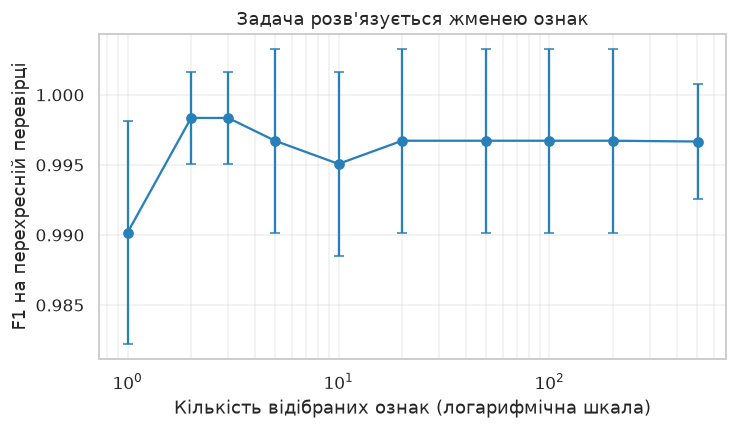

Одна ознака дає F1 = 0.9902; усі 503 ознак дають F1 = 0.9967


In [17]:
# --- Рисунок 7: скільки ознак насправді потрібно ---
fig, ax = plt.subplots(figsize=(6.8, 4))
ax.errorbar(curve_df["Кількість ознак"], curve_df["F1 (CV)"],
            yerr=curve_df["std"], marker="o", capsize=3, color="#2980b9")
ax.set_xscale("log")
ax.set_xlabel("Кількість відібраних ознак (логарифмічна шкала)")
ax.set_ylabel("F1 на перехресній перевірці")
ax.set_title("Задача розв'язується жменею ознак")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig(ASSETS / "07-feature-curve.png", bbox_inches="tight")
plt.show()

one = curve_df.iloc[0]
print(f"Одна ознака дає F1 = {one['F1 (CV)']:.4f}; "
      f"усі {X.shape[1]} ознак дають F1 = {curve_df.iloc[-1]['F1 (CV)']:.4f}")

## 8. Інтерпретація коефіцієнтів: співвідношення шансів (odds ratio)

Методичка зазначає, що логістична регресія оцінює **OR (odds ratio)** — співвідношення
шансів. Для бінарної ознаки коефіцієнт θᵢ означає: наявність ознаки множить шанси
на те, що файл шкідливий, у **e^θᵢ** разів.

In [18]:
coefs = pd.DataFrame({
    "Ознака": X.columns[kept],
    "Коефіцієнт θ": logreg_sel.coef_[0],
})
coefs["Odds ratio e^θ"] = np.exp(coefs["Коефіцієнт θ"])
coefs["|θ|"] = coefs["Коефіцієнт θ"].abs()
top = coefs.nlargest(15, "|θ|").drop(columns="|θ|").reset_index(drop=True)
top.round(3)

,Ознака,Коефіцієнт θ,Odds ratio e^θ
0,F_19,-3.271,0.038
1,F_20,2.900,18.165
2,F_139,1.972,7.183


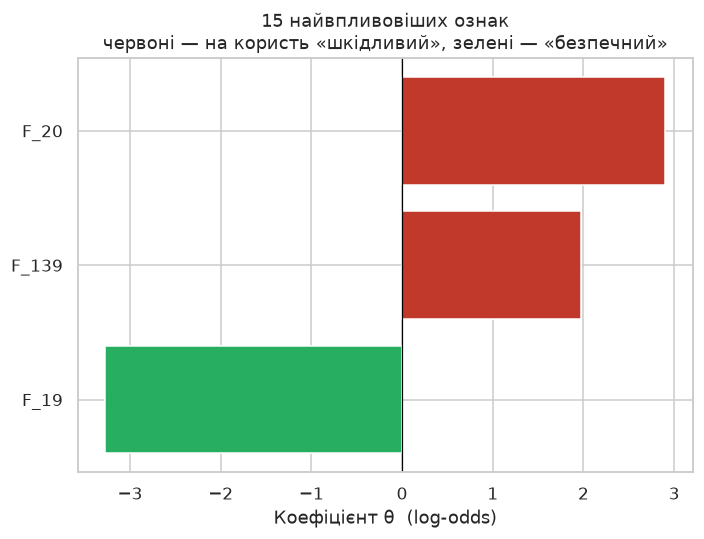

In [19]:
# --- Рисунок 3: найвпливовіші ознаки ---
fig, ax = plt.subplots(figsize=(6.5, 5))
t = top.sort_values("Коефіцієнт θ")
colors = ["#27ae60" if v < 0 else "#c0392b" for v in t["Коефіцієнт θ"]]
ax.barh(t["Ознака"], t["Коефіцієнт θ"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Коефіцієнт θ  (log-odds)")
ax.set_title("15 найвпливовіших ознак\nчервоні — на користь «шкідливий», зелені — «безпечний»")
plt.tight_layout()
plt.savefig(ASSETS / "03-coefficients.png", bbox_inches="tight")
plt.show()

## 9. Поріг відсікання k

Методичка: *«об'єкт належить до одного з класів {0; 1} з огляду на те, чи перевищує
його оцінка ймовірності поріг відсікання k»*. За замовчуванням k = 0.5, але це
довільний вибір. Побудуємо криві та подивимось, як зміна k торгує precision на recall.

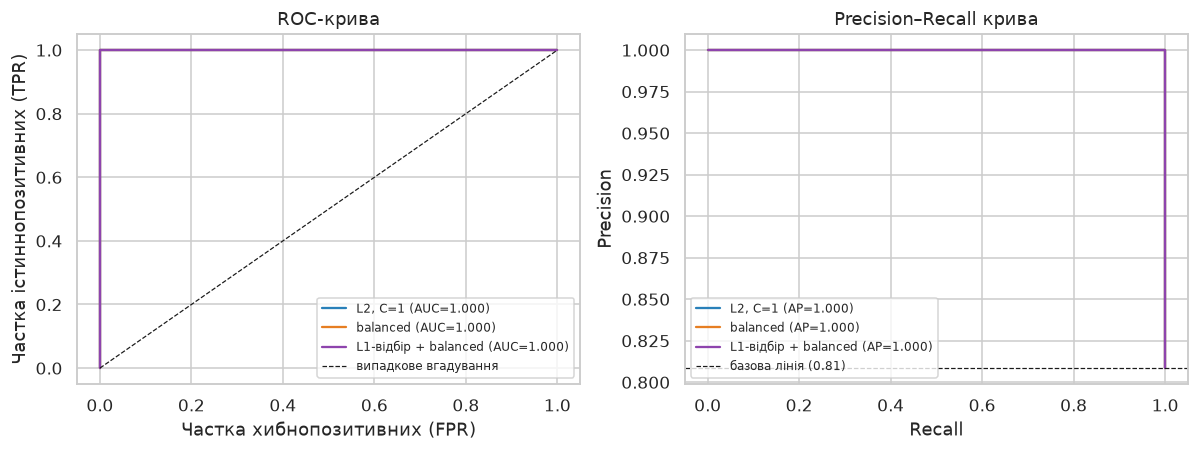

In [20]:
# --- Рисунок 4: ROC та precision-recall криві ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for name, proba, color in [("L2, C=1", y_proba, "#2980b9"),
                           ("balanced", y_proba_bal, "#e67e22"),
                           ("L1-відбір + balanced", y_proba_sel, "#8e44ad")]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})", color=color)
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, proba):.3f})", color=color)

axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8, label="випадкове вгадування")
axes[0].set_xlabel("Частка хибнопозитивних (FPR)")
axes[0].set_ylabel("Частка істиннопозитивних (TPR)")
axes[0].set_title("ROC-крива")
axes[0].legend(fontsize=8, loc="lower right")

axes[1].axhline(y_test.mean(), color="k", linestyle="--", linewidth=0.8,
                label=f"базова лінія ({y_test.mean():.2f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–Recall крива")
axes[1].legend(fontsize=8, loc="lower left")

plt.tight_layout()
plt.savefig(ASSETS / "04-roc-pr-curves.png", bbox_inches="tight")
plt.show()

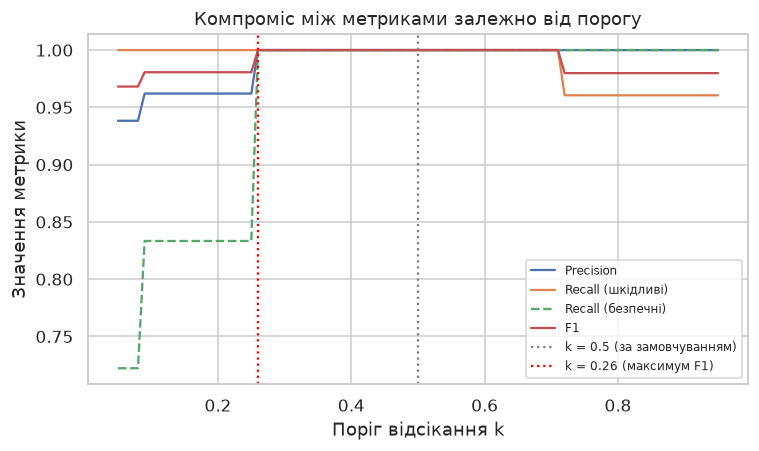

Максимум F1 = 1.000 при k = 0.26


In [21]:
# --- Рисунок 5: як поріг k впливає на метрики ---
thresholds = np.linspace(0.05, 0.95, 91)
rows = []
for k in thresholds:
    pred_k = (y_proba_sel >= k).astype(int)
    rows.append({
        "k": k,
        "Precision": precision_score(y_test, pred_k, zero_division=0),
        "Recall (шкідливі)": recall_score(y_test, pred_k, zero_division=0),
        "Recall (безпечні)": recall_score(y_test, pred_k, pos_label=0, zero_division=0),
        "F1": f1_score(y_test, pred_k, zero_division=0),
    })
thr_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4.2))
for col, style in [("Precision", "-"), ("Recall (шкідливі)", "-"),
                   ("Recall (безпечні)", "--"), ("F1", "-")]:
    ax.plot(thr_df["k"], thr_df[col], style, label=col)
best_k = thr_df.loc[thr_df["F1"].idxmax(), "k"]
ax.axvline(0.5, color="gray", linestyle=":", label="k = 0.5 (за замовчуванням)")
ax.axvline(best_k, color="red", linestyle=":", label=f"k = {best_k:.2f} (максимум F1)")
ax.set_xlabel("Поріг відсікання k")
ax.set_ylabel("Значення метрики")
ax.set_title("Компроміс між метриками залежно від порогу")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(ASSETS / "05-threshold.png", bbox_inches="tight")
plt.show()

print(f"Максимум F1 = {thr_df['F1'].max():.3f} при k = {best_k:.2f}")

## 10. Логістична функція Λ та зв'язок з нейронною мережею

Методичка вказує, що логістичну регресію можна подати як **одношарову нейронну
мережу з сигмоїдною функцією активації**: ваги мережі — це коефіцієнти регресії,
а вага поляризації — вільний член θ₀.

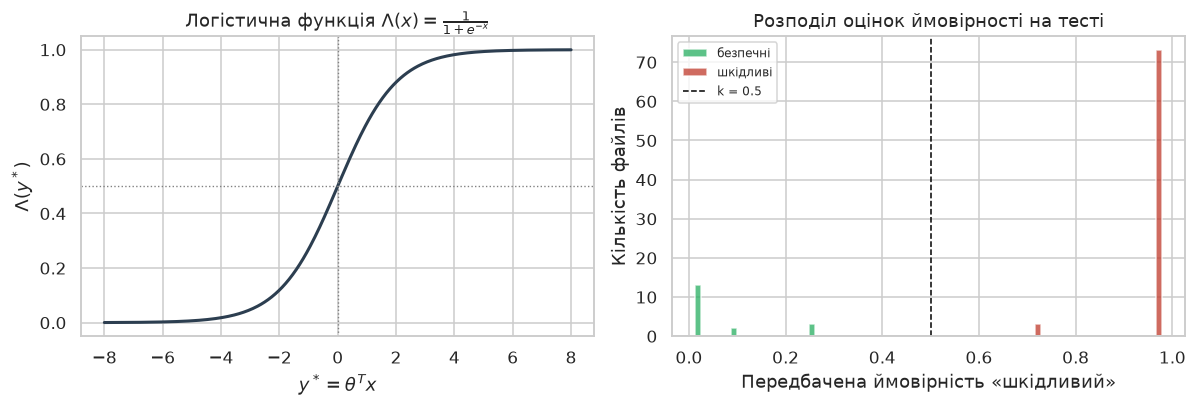

In [22]:
# --- Рисунок 6: сигмоїда та розподіл передбачених ймовірностей ---
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

x = np.linspace(-8, 8, 400)
axes[0].plot(x, 1/(1 + np.exp(-x)), color="#2c3e50", linewidth=2)
axes[0].axhline(0.5, color="gray", linestyle=":", linewidth=0.9)
axes[0].axvline(0, color="gray", linestyle=":", linewidth=0.9)
axes[0].set_xlabel(r"$y^* = \theta^T x$")
axes[0].set_ylabel(r"$\Lambda(y^*)$")
axes[0].set_title(r"Логістична функція $\Lambda(x)=\frac{1}{1+e^{-x}}$")

axes[1].hist(y_proba_sel[y_test == 0], bins=20, alpha=0.75, label="безпечні", color="#27ae60")
axes[1].hist(y_proba_sel[y_test == 1], bins=20, alpha=0.75, label="шкідливі", color="#c0392b")
axes[1].axvline(0.5, color="black", linestyle="--", linewidth=1, label="k = 0.5")
axes[1].set_xlabel("Передбачена ймовірність «шкідливий»")
axes[1].set_ylabel("Кількість файлів")
axes[1].set_title("Розподіл оцінок ймовірності на тесті")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(ASSETS / "06-sigmoid.png", bbox_inches="tight")
plt.show()

## 11. Підсумкова таблиця

In [23]:
summary = pd.DataFrame(results).set_index("Модель").round(3)
summary

,Точність,Precision (шкідл.),Recall (шкідл.),Recall (безпеч.),F1,ROC-AUC,PR-AUC
Модель,,,,,,,
Базова лінія (завжди «шкідливий»),0.809,0.809,1.0,0.0,0.894,0.5,0.809
"Логістична регресія (L2, C=1)",1.000,1.000,1.0,1.0,1.000,1.0,1.000
Логістична регресія (balanced),1.000,1.000,1.0,1.0,1.000,1.0,1.000
L1-відбір (3 ознак) + balanced,1.000,1.000,1.0,1.0,1.000,1.0,1.000


In [24]:
# Зберігаємо підсумок, щоб вставити у звіт без ручного переписування
summary.to_csv("data/results-summary.csv")
print(summary.to_markdown())

| Модель                            |   Точність |   Precision (шкідл.) |   Recall (шкідл.) |   Recall (безпеч.) |    F1 |   ROC-AUC |   PR-AUC |
|:----------------------------------|-----------:|---------------------:|------------------:|-------------------:|------:|----------:|---------:|
| Базова лінія (завжди «шкідливий») |      0.809 |                0.809 |                 1 |                  0 | 0.894 |       0.5 |    0.809 |
| Логістична регресія (L2, C=1)     |      1     |                1     |                 1 |                  1 | 1     |       1   |    1     |
| Логістична регресія (balanced)    |      1     |                1     |                 1 |                  1 | 1     |       1   |    1     |
| L1-відбір (3 ознак) + balanced    |      1     |                1     |                 1 |                  1 | 1     |       1   |    1     |
